# 02. NBA 2024-25: 피타고라스 기대 승률과 실제 승률

같은 방법을 **NBA 2024-25 정규시즌 30개 팀 기록**에 적용했다. 상관관계는 높지만, 지수 2를 그대로 쓰면 기대 승률 값이 실제 승률과 크게 어긋난다. 이 문제는 04 노트북에서 다룬다.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
NBA18 = pd.read_excel('../data/nba-2025-asplayed.xlsx')
NBA18

,Team,Wins,Points_For,Points_Against
0,Cleveland Cavaliers,64,9999,9217
1,Memphis Grizzlies,48,9980,9582
2,Denver Nuggets,50,9902,9583
3,Oklahoma City Thunder,68,9881,8826
4,Atlanta Hawks,40,9691,9784
5,Chicago Bulls,39,9660,9788
6,Indiana Pacers,50,9624,9441
7,Boston Celtics,61,9534,8787
8,New York Knicks,51,9494,9158
9,Sacramento Kings,40,9490,9451


In [3]:
NBA18 = NBA18.rename(columns={'Wins':'result','Points_For':'PTS','Points_Against':'PTSAGN'})
NBA18

,Team,result,PTS,PTSAGN
0,Cleveland Cavaliers,64,9999,9217
1,Memphis Grizzlies,48,9980,9582
2,Denver Nuggets,50,9902,9583
3,Oklahoma City Thunder,68,9881,8826
4,Atlanta Hawks,40,9691,9784
5,Chicago Bulls,39,9660,9788
6,Indiana Pacers,50,9624,9441
7,Boston Celtics,61,9534,8787
8,New York Knicks,51,9494,9158
9,Sacramento Kings,40,9490,9451


In [4]:
NBA18['wpc'] = NBA18['result'] / 82
NBA18['pyth'] = NBA18['PTS']**2 / (NBA18['PTS']**2+NBA18['PTSAGN']**2)
NBA18

,Team,result,PTS,PTSAGN,wpc,pyth
0,Cleveland Cavaliers,64,9999,9217,0.780488,0.540628
1,Memphis Grizzlies,48,9980,9582,0.585366,0.520337
2,Denver Nuggets,50,9902,9583,0.609756,0.516367
3,Oklahoma City Thunder,68,9881,8826,0.829268,0.556217
4,Atlanta Hawks,40,9691,9784,0.487805,0.495225
5,Chicago Bulls,39,9660,9788,0.475610,0.493419
6,Indiana Pacers,50,9624,9441,0.609756,0.509598
7,Boston Celtics,61,9534,8787,0.743902,0.540705
8,New York Knicks,51,9494,9158,0.621951,0.518008
9,Sacramento Kings,40,9490,9451,0.487805,0.502059


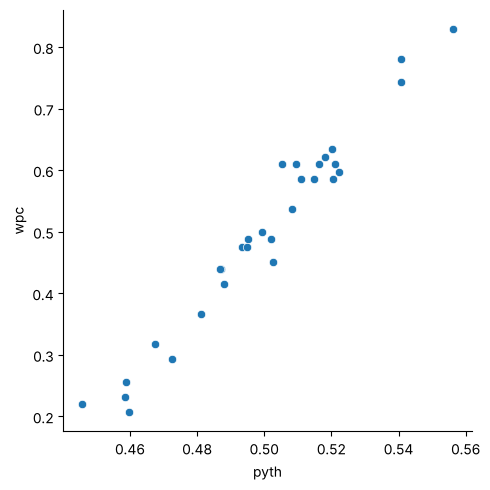

In [5]:
sns.relplot(x="pyth",y="wpc",data=NBA18)

In [6]:
pyth_lm = smf.ols(formula='wpc ~ pyth',data=NBA18).fit()
pyth_lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    wpc   R-squared:                       0.964
Model:                            OLS   Adj. R-squared:                  0.963
Method:                 Least Squares   F-statistic:                     753.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.75e-22
Time:                        17:07:07   Log-Likelihood:                 62.319
No. Observations:                  30   AIC:                            -120.6
Df Residuals:                      28   BIC:                            -117.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.5369      0.111    -22.898      0.000      -2.764      -2.310
pyth           6.0747      0.221     27.448      0.000       5.621       6.528
==============================================================================
Omnibus:                        0.730   Durbin-Watson:                   2.237
Prob(Omnibus):                  0.694   Jarque-Bera (JB):                0.200
Skew:                           0.186   Prob(JB):                        0.905
Kurtosis:                       3.145   Cond. No.                         48.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""